In [10]:
import pandas as pd

file_path = r"C:\Users\ADMIN\Downloads\(102) Lead Filters.csv"

df = pd.read_csv(
    file_path,
    encoding="latin1",
    skiprows=1,
    engine="python",
    on_bad_lines="skip"
)

print(df.head())
print("dataset shape:",df.shape)

df.columns = df.columns.str.strip()

print(df.columns.tolist())

                                                   ?9LìÒÈsbgÙ®|Èl!õùUSh9i°br:"y_dlÀóD¿ý|-NÈR"4ø2ÏGÇ% õZ´4ñËyÄ7\tÃ«ÈðÉ¨Þ  ÿÿ PK    ! BL Z¼  L     xl/workbook.xml¤UÛn£0}_iÿùI 
*­º¡ÑFÚ]E½¾Dªpc³¶iRUý÷CHæ¥Û"ðmàøÌÌsv±)¹óD...  SRË9h¯%}ä?ö=B°9ÁÇú¢OÌæpÇJEdí°¢=ö¿A...                                                                                                     
)AhAGÜP%¡#)Èv¯J´Á                                                                     None                                                                                                     
Â¹¦kÖ09Bh %YLæzJLáÔ'hÏî4Dkö°Ô³T®P³72&Ç5ó...  8æø(%£¦"Dô¹Ò4jÎ0u2jsÐÊMYÞË´äúSì­´·· ...                                                                                                     
y ÑèÔ!+øÁEò¼üfMyÎkÁ£úå«Kª5=|t ÈG)så¢...  ËôïfäÉÇÕß   ÿÿ PK    ! PÊJ 2    ...                                                                                             

In [16]:
import pandas as pd

file_path = r"C:\Users\ADMIN\Downloads\(102) Lead Filters.xlsx"

df = pd.read_excel(file_path, header=1)

print(df.head())
print("Rows and columns:", df.shape)
print("Column names:", df.columns.tolist())
print("Missing values:")
print(df.isnull().sum())

df.columns = df.columns.str.strip()

print(df.columns.tolist())

print("before cleaning:",df.shape)
df=df.drop_duplicates()
print("after cleaning;",df.shape)

print(df.isnull().sum())

df["Tags"]= df["Tags"].fillna("Not Available")

print(df[["Created Date", "Last Contact"]].head(10).to_string())

df.to_excel(r"C:\Users\ADMIN\Downloads\(102) Lead Filters_Cleaned.xlsx",index=False)
print("Data Cleaning completed")

      #         Name City State Country  Zip Code Lead value          Status  \
0  2402  Padma Priya  NaN   NaN   India       NaN         ₹0         Invalid   
1  2401      No Name  NaN   NaN   India       NaN         ₹0         Invalid   
2  2400      Krishna  NaN   NaN   India       NaN         ₹0        Followup   
3  2399  Muthu Kumar  NaN   NaN   India       NaN         ₹0        Followup   
4  2398  Sahabu Deen  NaN   NaN   India       NaN         ₹0  Not interested   

      Source                   Created Date                   Last Contact  \
0  dm 24,999  173564222331-12-2024 16:20:23  173564222331-12-2024 16:20:23   
1  dm 24,999  173564217631-12-2024 16:19:36  173564217631-12-2024 16:19:36   
2  dm 24,999  173564214031-12-2024 16:19:00  173564214031-12-2024 16:19:00   
3  dm 24,999  173564210231-12-2024 16:18:22  173564210231-12-2024 16:18:22   
4  dm 24,999  173564199331-12-2024 16:16:33  173564199331-12-2024 16:16:33   

  Public        Assigned Tags  
0    Yes  Harish K

In [27]:
print(df["Created Date"].head(5).tolist())
print(df["Last Contact"].head(5).tolist())

df_test = df.copy()

for col in ["Created Date", "Last Contact"]:
    df_test[col] = (
        df_test[col]
        .astype("string")
        .str.extract(r"(\d{2}-\d{2}-\d{4} \d{2}:\d{2}:\d{2})", expand=False)
    )

    df_test[col] = pd.to_datetime(
        df_test[col],
        format="%d-%m-%Y %H:%M:%S",
        errors="coerce"
    )

print(df_test[["Created Date", "Last Contact"]].head())

print(df_test[["Created Date", "Last Contact"]].isna().sum())
print(df_test[["Created Date", "Last Contact"]].head(10))

# Check original values that could not be converted
bad_dates = df.loc[
    df_test["Last Contact"].isna(),
    ["Last Contact"]
]

print(bad_dates.head(20))
print("Total problematic dates:", len(bad_dates))

print(df_test[["Created Date", "Last Contact"]].isnull().sum())

# Check original Last Contact values
missing_rows = df["Last Contact"].isna()

print("Originally missing:", missing_rows.sum())
print(df.loc[missing_rows, ["Name", "Status", "Last Contact"]].head(10))

print("Missing values in all columns:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)
print("Original missing values:")
print(df["Last Contact"].isnull().sum())

print("\nMissing values by column:")
print(df.isnull().sum())
df_clean = df.copy()

df_clean["Created Date"] = df_test["Created Date"]
df_clean["Last Contact"] = df_test["Last Contact"]

print(df_clean[["Created Date", "Last Contact"]].dtypes)
output_path = r"C:\Users\ADMIN\Downloads\Lead_Filters_Cleaned.xlsx"

df_clean.to_excel(output_path, index=False)

print("Cleaned dataset saved successfully!")

['173564222331-12-2024 16:20:23', '173564217631-12-2024 16:19:36', '173564214031-12-2024 16:19:00', '173564210231-12-2024 16:18:22', '173564199331-12-2024 16:16:33']
['173564222331-12-2024 16:20:23', '173564217631-12-2024 16:19:36', '173564214031-12-2024 16:19:00', '173564210231-12-2024 16:18:22', '173564199331-12-2024 16:16:33']
         Created Date        Last Contact
0 2024-12-31 16:20:23 2024-12-31 16:20:23
1 2024-12-31 16:19:36 2024-12-31 16:19:36
2 2024-12-31 16:19:00 2024-12-31 16:19:00
3 2024-12-31 16:18:22 2024-12-31 16:18:22
4 2024-12-31 16:16:33 2024-12-31 16:16:33
Created Date      0
Last Contact    454
dtype: int64
         Created Date        Last Contact
0 2024-12-31 16:20:23 2024-12-31 16:20:23
1 2024-12-31 16:19:36 2024-12-31 16:19:36
2 2024-12-31 16:19:00 2024-12-31 16:19:00
3 2024-12-31 16:18:22 2024-12-31 16:18:22
4 2024-12-31 16:16:33 2024-12-31 16:16:33
5 2024-12-31 16:15:31 2024-12-31 16:15:31
6 2024-12-31 16:13:43 2024-12-31 16:13:43
7 2024-12-31 16:12:35 2024-

In [32]:
# Check missing values in each column
missing = df_clean.isnull().sum()

print("Missing values in each column:")
print(missing[missing > 0])
missing_percent = (
    df_clean.isnull().sum() / len(df_clean) * 100
).round(2)

print(missing_percent[missing_percent > 0])
print(df_clean["Country"].value_counts(dropna=False))



Missing values in each column:
City             824
State           1998
Country          458
Zip Code        2002
Last Contact     454
dtype: int64
City            41.00
State           99.40
Country         22.79
Zip Code        99.60
Last Contact    22.59
dtype: float64
Country
India    1552
NaN       458
Name: count, dtype: int64


In [73]:
df.drop(columns=["Zip Code"],inplace=True)
print("zip code columns removed.")

zip code columns removed.


In [34]:
# Remove extra spaces from text columns
text_cols = df_clean.select_dtypes(include="object").columns

for col in text_cols:
    df_clean[col] = df_clean[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

print("Text cleaning completed!")

print(df_clean["Status"].value_counts(dropna=False))
print("Duplicate IDs:", df_clean["#"].duplicated().sum())
print(df_clean["#"].value_counts().head(10))

Text cleaning completed!
Status
New                                  553
Followup                             547
Not answering                        276
Not interested                       177
call later                            61
wrong lead                            51
Switched off                          45
Invalid                               43
Not Reachable                         38
Details has sent through Whatsapp     36
Not Responding                        32
Customer                              28
out of service                        25
Close Follow up                       25
On process                            10
Already have one                       9
Closed by other team                   8
Need to get requirements               7
Not Required @ Present                 7
Other Language                         6
Appointment                            5
Looking For Job                        4
Wrong Num                              3
Proposal Sent            

In [50]:
# Check cleaned status values
print(df['Status'].unique())
print(df.isnull().sum())
missing = df.isnull().sum()

missing_percentage = (
    df.isnull().sum() / len(df) * 100
).round(2)

missing_report = pd.DataFrame({
    'Missing Values': missing,
    'Missing Percentage': missing_percentage
})

print(missing_report)
print(
    missing_report.sort_values(
        by='Missing Percentage',
        ascending=False
    )
)

['Invalid' 'Followup' 'Not interested' 'Switched off' 'call later'
 'Details has sent through Whatsapp' 'Already have one' 'Proposal Sent'
 'Not Responding' 'out of service' 'Competitor' 'Not Required @ Present'
 'looking for candidate' 'New' 'wrong lead' 'Looking For Job' 'On process'
 'Proposal Shared' 'Appointment' 'Close Follow up' 'Closed by other team'
 'Not Reachable' 'Not answering' 'Customer' 'Need to get requirements'
 'Ring Not Answering' 'Other Language' 'follow-up' 'Expected price low'
 'Unsucessful Call' 'Wrong Num' 'Need to send our profile' 'Didnt Enquire']
#                  0
Name               0
City             824
State           1998
Country          458
Zip Code        2002
Lead value         0
Status             0
Source             0
Created Date       0
Last Contact     454
Public             0
Assigned           0
Tags               0
dtype: int64
              Missing Values  Missing Percentage
#                          0                0.00
Name           

In [54]:
pd.set_option('display.max_rows', None)

print(missing_report.sort_values(
    by='Missing Percentage',
    ascending=False
))

missing_report = missing_report[
    missing_report['Missing Values'] > 0
].sort_values(
    by='Missing Percentage',
    ascending=False
)

display(missing_report)

print("Dataset shape:", df.shape)

display(
    missing_report.sort_values(
        by="Missing Percentage",
        ascending=False
    )
)

              Missing Values  Missing Percentage
Zip Code                2002               99.60
State                   1998               99.40
City                     824               41.00
Country                  458               22.79
Last Contact             454               22.59


,Missing Values,Missing Percentage
Zip Code,2002,99.60
State,1998,99.40
City,824,41.00
Country,458,22.79
Last Contact,454,22.59


Dataset shape: (2010, 14)


,Missing Values,Missing Percentage
Zip Code,2002,99.60
State,1998,99.40
City,824,41.00
Country,458,22.79
Last Contact,454,22.59


In [56]:
# Count leads by status
status_counts = df['Status'].value_counts()

display(status_counts)

status_percentage = (
    df['Status'].value_counts(normalize=True) * 100
).round(2)

status_report = pd.DataFrame({
    'Lead Count': df['Status'].value_counts(),
    'Percentage (%)': status_percentage
})

display(status_report)

Status
New                                  553
Followup                             547
Not answering                        276
Not interested                       177
call later                            61
wrong lead                            51
Switched off                          45
Invalid                               43
Not Reachable                         38
Details has sent through Whatsapp     36
Not Responding                        32
Customer                              28
out of service                        25
Close Follow up                       25
On process                            10
Already have one                       9
Closed by other team                   8
Need to get requirements               7
Not Required @ Present                 7
Other Language                         6
Appointment                            5
Looking For Job                        4
Wrong Num                              3
Proposal Sent                          2
Competito

,Lead Count,Percentage (%)
Status,,
New,553,27.51
Followup,547,27.21
Not answering,276,13.73
Not interested,177,8.81
call later,61,3.03
wrong lead,51,2.54
Switched off,45,2.24
Invalid,43,2.14
Not Reachable,38,1.89


In [57]:
# Analyze lead sources
source_counts = df['Source'].value_counts()

display(source_counts)

Source
3 + 1 DM                   640
India SMM campaign         348
FB-DM                      298
Instagram & Facebook       244
Chennai Database           136
DM 25k Naresh              134
DM Reel new                 61
WhatsApp DM Enquiries       46
dm 24,999                   25
Dm 25k Nov                  19
App development 26-7-24     15
FB-hwp                       7
5 services                   7
Mobile App Lead              6
Employee Reference           5
App Dev                      5
Google Extractor             2
Ecommerce Lead               2
Charu Leads                  2
WA Valid Leads               2
6999 Website Leads           2
Dm 24,999 Hq                 1
Dm24,999-Vivek               1
Our Services                 1
Dubai SMM Campaign           1
Name: count, dtype: int64

Matplotlib is building the font cache; this may take a moment.


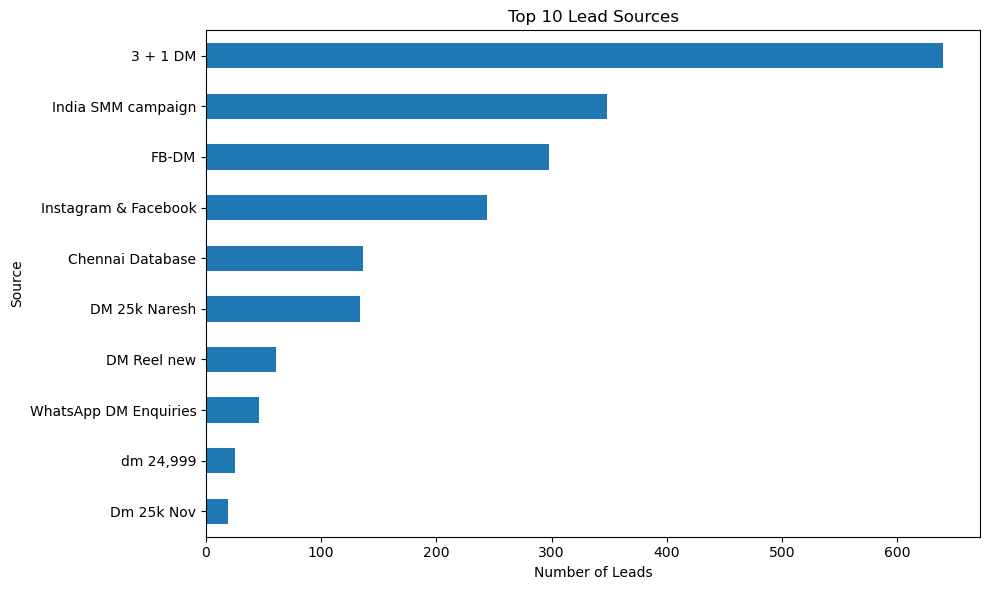

In [58]:
import matplotlib.pyplot as plt

source_counts = df['Source'].value_counts()

source_counts.head(10).sort_values().plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('Top 10 Lead Sources')
plt.xlabel('Number of Leads')
plt.ylabel('Source')
plt.tight_layout()
plt.show()

In [59]:
# Compare lead statuses across sources
source_status = pd.crosstab(
    df['Source'],
    df['Status']
)

display(
    source_status.sort_values(
        by='Customer',
        ascending=False
    ).head(10)
)

Status,Already have one,Appointment,Close Follow up,Closed by other team,Competitor,Customer,Details has sent through Whatsapp,Didnt Enquire,Expected price low,Followup,...,Proposal Shared,Ring Not Answering,Switched off,Unsucessful Call,Wrong Num,call later,follow-up,looking for candidate,out of service,wrong lead
Source,,,,,,,,,,,,,,,,,,,,,
3 + 1 DM,0,1,16,3,1,19,2,0,0,276,...,0,0,11,0,0,14,0,0,9,19
Employee Reference,0,0,0,0,0,2,0,0,0,2,...,0,0,0,0,0,0,0,0,0,0
Google Extractor,0,0,0,0,0,2,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
WhatsApp DM Enquiries,0,0,2,2,0,1,3,0,0,6,...,1,1,5,0,0,3,0,0,2,2
Instagram & Facebook,0,1,0,1,0,1,0,2,0,4,...,0,0,4,0,3,0,0,0,3,18
India SMM campaign,0,0,0,0,0,1,14,0,0,22,...,0,0,4,0,0,13,0,0,0,3
FB-DM,3,3,0,1,1,1,9,0,0,148,...,0,0,8,0,0,15,0,1,5,3
Dubai SMM Campaign,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DM Reel new,1,0,1,1,0,0,0,0,0,5,...,0,0,2,2,0,1,0,0,0,0


In [60]:
# Compare lead statuses across sources
source_status = pd.crosstab(
    df['Source'],
    df['Status']
)

display(
    source_status.sort_values(
        by='Customer',
        ascending=False
    ).head(10)
)

Status,Already have one,Appointment,Close Follow up,Closed by other team,Competitor,Customer,Details has sent through Whatsapp,Didnt Enquire,Expected price low,Followup,...,Proposal Shared,Ring Not Answering,Switched off,Unsucessful Call,Wrong Num,call later,follow-up,looking for candidate,out of service,wrong lead
Source,,,,,,,,,,,,,,,,,,,,,
3 + 1 DM,0,1,16,3,1,19,2,0,0,276,...,0,0,11,0,0,14,0,0,9,19
Employee Reference,0,0,0,0,0,2,0,0,0,2,...,0,0,0,0,0,0,0,0,0,0
Google Extractor,0,0,0,0,0,2,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
WhatsApp DM Enquiries,0,0,2,2,0,1,3,0,0,6,...,1,1,5,0,0,3,0,0,2,2
Instagram & Facebook,0,1,0,1,0,1,0,2,0,4,...,0,0,4,0,3,0,0,0,3,18
India SMM campaign,0,0,0,0,0,1,14,0,0,22,...,0,0,4,0,0,13,0,0,0,3
FB-DM,3,3,0,1,1,1,9,0,0,148,...,0,0,8,0,0,15,0,1,5,3
Dubai SMM Campaign,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
DM Reel new,1,0,1,1,0,0,0,0,0,5,...,0,0,2,2,0,1,0,0,0,0


In [61]:
# Total leads per source
total_by_source = df['Source'].value_counts()

# Customers per source
customers_by_source = (
    df[df['Status'].str.strip().str.lower() == 'customer']
    .groupby('Source')
    .size()
)

# Combine into a report
conversion_report = pd.DataFrame({
    'Total Leads': total_by_source,
    'Customers': customers_by_source
}).fillna(0)

conversion_report['Customers'] = (
    conversion_report['Customers'].astype(int)
)

conversion_report['Conversion Rate (%)'] = (
    conversion_report['Customers']
    / conversion_report['Total Leads'] * 100
).round(2)

display(
    conversion_report.sort_values(
        'Conversion Rate (%)',
        ascending=False
    ).head(10)
)

,Total Leads,Customers,Conversion Rate (%)
Source,,,
Dubai SMM Campaign,1,1,100.00
Google Extractor,2,2,100.00
Employee Reference,5,2,40.00
3 + 1 DM,640,19,2.97
WhatsApp DM Enquiries,46,1,2.17
Instagram & Facebook,244,1,0.41
FB-DM,298,1,0.34
India SMM campaign,348,1,0.29
App development 26-7-24,15,0,0.00


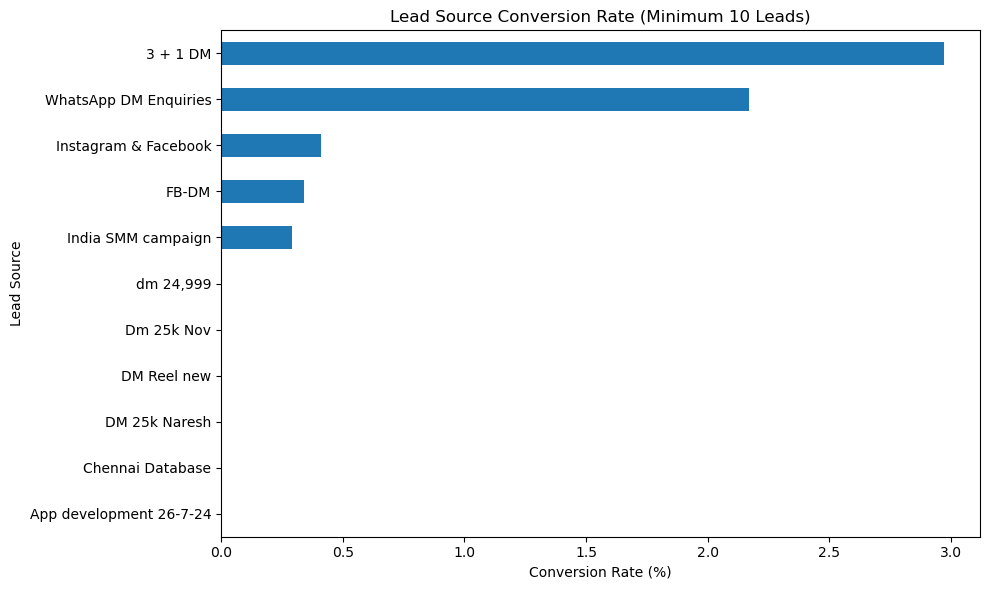

In [62]:
# Filter sources with at least 10 leads
reliable_sources = conversion_report[
    conversion_report['Total Leads'] >= 10
].sort_values(
    'Conversion Rate (%)',
    ascending=True
)

# Plot conversion rates
reliable_sources['Conversion Rate (%)'].plot(
    kind='barh',
    figsize=(10, 6)
)

plt.title('Lead Source Conversion Rate (Minimum 10 Leads)')
plt.xlabel('Conversion Rate (%)')
plt.ylabel('Lead Source')
plt.tight_layout()
plt.show()

In [63]:
# Count the most common follow-up-related statuses
followup_statuses = [
    'New',
    'Followup',
    'call later',
    'Not answering',
    'Not Responding',
    'Not Reachable',
    'Ring Not Answering'
]

followup_report = (
    df[df['Status'].isin(followup_statuses)]['Status']
    .value_counts()
)

display(followup_report)

Status
New                   553
Followup              547
Not answering         276
call later             61
Not Reachable          38
Not Responding         32
Ring Not Answering      1
Name: count, dtype: int64

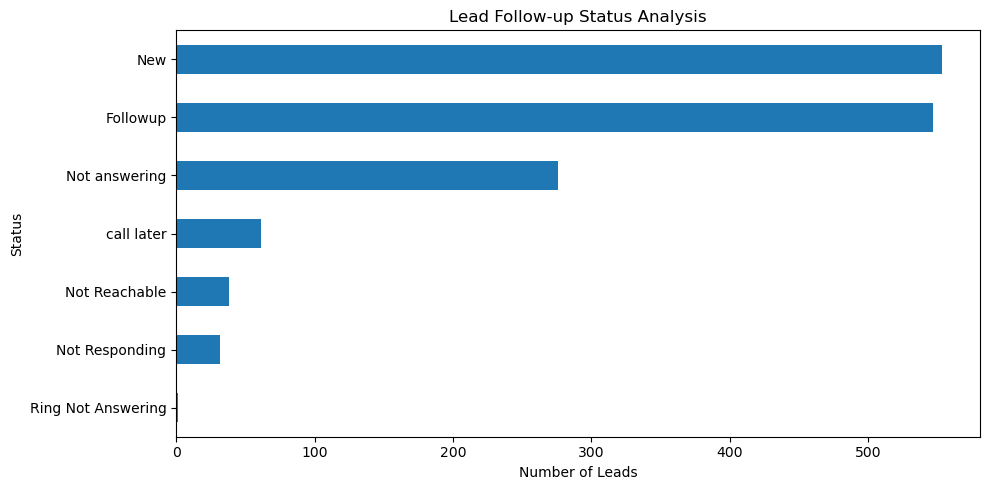

In [64]:
import matplotlib.pyplot as plt

followup_report.sort_values().plot(
    kind='barh',
    figsize=(10, 5)
)

plt.title('Lead Follow-up Status Analysis')
plt.xlabel('Number of Leads')
plt.ylabel('Status')
plt.tight_layout()
plt.show()

In [ ]:
followup_report.to_csv('lead_followup_report.csv')

print("Follow-up report saved successfully!")

status_report.to_csv(
    'lead_status_report.csv',
    index=True
)


conversion_report.to_csv(
    'lead_source_conversion_report.csv',
    index=True
)

print("Conversion report saved successfully!")


Follow-up report saved successfully!
Conversion report saved successfully!


FINAL LEAD ANALYSIS SUMMARY


,Metric,Value
0,Total Leads,2010.00
1,Unique Lead Sources,25.00
2,Total Customers,28.00
3,Overall Conversion Rate (%),1.39
4,New Leads,553.00
5,Follow-up Leads,547.00
6,Not Answering,276.00


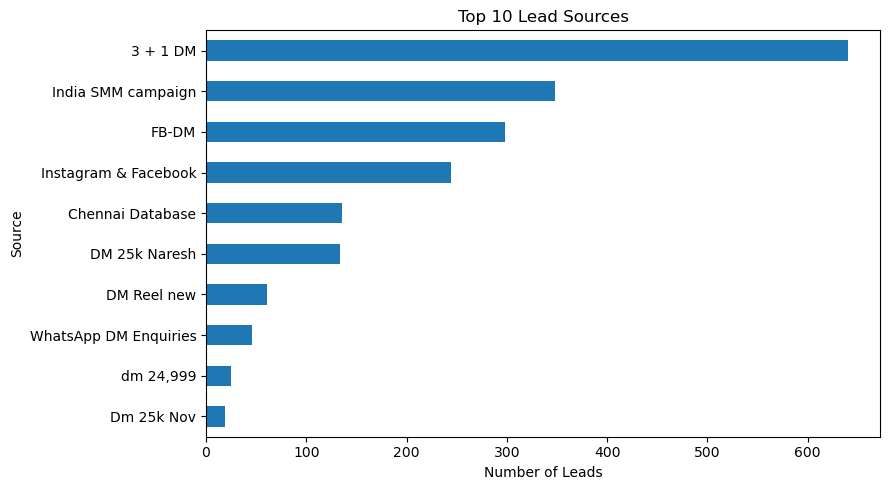

SUCCESS: All reports and chart saved!


In [70]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Overall summary
total_leads = len(df)
total_customers = (
    df['Status'].str.strip().str.lower() == 'customer'
).sum()

summary_report = pd.DataFrame({
    'Metric': [
        'Total Leads',
        'Unique Lead Sources',
        'Total Customers',
        'Overall Conversion Rate (%)',
        'New Leads',
        'Follow-up Leads',
        'Not Answering'
    ],
    'Value': [
        total_leads,
        df['Source'].nunique(),
        total_customers,
        round(total_customers / total_leads * 100, 2)
            if total_leads else 0,
        (df['Status'].str.strip().str.lower() == 'new').sum(),
        (df['Status'].str.strip().str.lower() == 'followup').sum(),
        (df['Status'].str.strip().str.lower() == 'not answering').sum()
    ]
})

print("FINAL LEAD ANALYSIS SUMMARY")
display(summary_report)

# 2. Save all reports
summary_report.to_csv('final_lead_analysis_summary.csv', index=False)
conversion_report.to_csv('lead_source_conversion_report.csv')
followup_report.to_csv('lead_followup_report.csv')

# 3. Save top 10 lead sources chart
df['Source'].value_counts().head(10).sort_values().plot(
    kind='barh', figsize=(9, 5), title='Top 10 Lead Sources'
)
plt.xlabel('Number of Leads')
plt.tight_layout()
plt.savefig('top_10_lead_sources.png', dpi=150, bbox_inches='tight')
plt.show()

print("SUCCESS: All reports and chart saved!")

In [71]:
import os

files = [
    'final_lead_analysis_summary.csv',
    'lead_source_conversion_report.csv',
    'lead_followup_report.csv',
    'top_10_lead_sources.png'
]

for file in files:
    print(f"{file}: {'Saved' if os.path.exists(file) else 'Not found'}")

final_lead_analysis_summary.csv: Saved
lead_source_conversion_report.csv: Saved
lead_followup_report.csv: Saved
top_10_lead_sources.png: Saved
